1

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

apartments = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/appartments_data_set.csv"
)

apartments = apartments[
    (apartments["ceiling_height"] >= 2) &
    (apartments["ceiling_height"] <= 6)
]

apartments = apartments.dropna(subset=["floors_total"])

apartments["living_area"] = apartments["living_area"].fillna(apartments["living_area"].median())
apartments["kitchen_area"] = apartments["kitchen_area"].fillna(apartments["kitchen_area"].median())

apartments["balcony"] = apartments["balcony"].fillna(0)

apartments["first_day_exposition"] = pd.to_datetime(apartments["first_day_exposition"])

apartments["floors_total"] = apartments["floors_total"].astype(int)
apartments["balcony"] = apartments["balcony"].astype(int)

apartments.head()

,Unnamed: 0,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,kitchen_area,balcony,locality_name,days_exposition
0,0,7312500.0,108.0,2024-05-15,3,2.70,16,51.0,8,NaN,False,25.0,0,Kyiv,NaN
4,4,5625000.0,100.0,2024-06-12,2,3.03,14,32.0,13,NaN,False,41.0,0,Kyiv,121.0
9,9,3037500.0,61.0,2024-03-10,3,2.50,9,43.6,7,NaN,False,6.5,2,Kyiv,289.0
10,10,2840625.0,39.6,2024-04-15,1,2.67,12,20.3,3,NaN,False,8.5,0,Kyiv,137.0
13,13,1996875.0,42.8,2024-05-16,2,2.56,5,27.0,5,NaN,False,5.2,1,Vyshneve,366.0


2

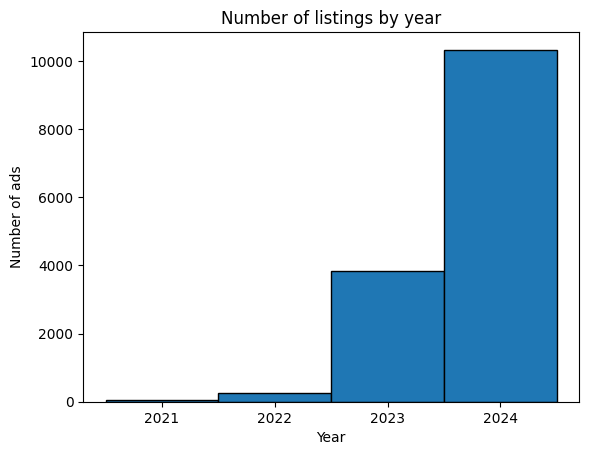

In [57]:
years = apartments["first_day_exposition"].dt.year.dropna()

bins = [year - 0.5 for year in range(years.min(), years.max() + 2)]

plt.hist(years, bins=bins, edgecolor="black")

plt.title("Number of listings by year")
plt.xlabel("Year")
plt.ylabel("Number of ads")
plt.xticks(range(years.min(), years.max() + 1))
plt.show()

3

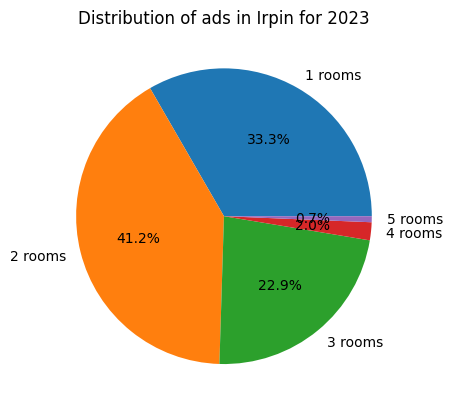

In [58]:
irpin_2023 = apartments[
    (apartments["locality_name"] == "Irpin") &
    (apartments["first_day_exposition"].dt.year == 2023)
]

rooms = sorted(irpin_2023["rooms"].dropna().unique())

counts = []

for room in rooms:
    count = len(irpin_2023[irpin_2023["rooms"] == room])
    counts.append(count)

labels = [str(room) + " rooms" for room in rooms]

plt.pie(counts, labels=labels, autopct="%1.1f%%")

plt.title("Distribution of ads in Irpin for 2023")
plt.show()

4

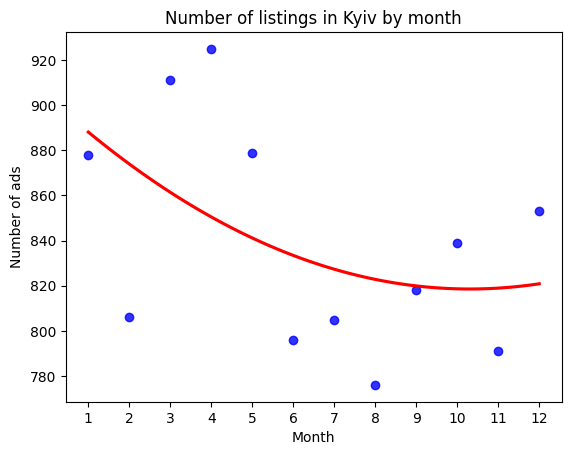

In [59]:
kyiv = apartments[apartments["locality_name"] == "Kyiv"]

months = kyiv["first_day_exposition"].dt.month.dropna()

month_numbers = list(range(1, 13))
counts = []

for month in month_numbers:
    count = len(months[months == month])
    counts.append(count)

sns.regplot(
    x=month_numbers,
    y=counts,
    order=2,
    ci=None,
    scatter_kws={"color": "blue"},
    line_kws={"color": "red"}
)

plt.title("Number of listings in Kyiv by month")
plt.xlabel("Month")
plt.ylabel("Number of ads")
plt.xticks(month_numbers)
plt.show()

Количество объявлений о продаже квартир в Киеве в течение года менялось неравномерно. Наибольшее количество объявлений наблюдалось в апреле, наименьшее — в августе. Аппроксимационная кривая показывает общую тенденцию к снижению количества объявлений с начала года до ноября, после чего наблюдается небольшой рост в декабре. При этом фактические значения заметно колеблются от месяца к месяцу.